In [18]:
import os
import pandas as pd 
from pathlib import Path

import matplotlib.pyplot as plt
import seaborn as sns

from morph_utils.templates import load_layer_template

import sys
sys.path.append('/root/capsule/code/figures') 
from morphology_utils import add_swc_paths


plt.rcParams['pdf.fonttype'] = 42 # ensures that the text is editable when imported into Illustrator


In [19]:
depth_type = 'layer' # depth_in_layer_norm used to define superficial/deep L2/3 IT groups
# depth_type = 'pia' # depth_from_pia_norm used to define superficial/deep L2/3 IT groups

In [20]:
def combine_layers_23(data, depth_type='layer'):

    #combine Layers 2 & 3 --? Layer2/3
    data['layer_new'] = data['layer'].replace({'Layer2': 'Layer2/3', 'Layer3': 'Layer2/3'})

    if depth_type == 'pia' :
        # We are defining L2/3 superficial & deep groups using depth_from_pia_norm, 
        # no need to calculate the depth_in_layer_norm for this new combined L2/3
        return data

    #Layer thickness for combo layer 2/3
    data['layer_thickness_um_new'] = data['layer_thickness_um']
    mask = data['layer_new'].isin(['Layer2/3'])
    data.loc[mask, 'layer_thickness_um_new'] = data.loc[mask, ['Layer2', 'Layer3']].sum(axis=1)

    # add Layer2 thickness to depth_in_layer_um_new for cells in Layer3
    data['depth_in_layer_um_new'] = data['depth_in_layer_um']
    data.loc[data['layer'] == 'Layer3', 'depth_in_layer_um_new'] += data.loc[data['layer'] == 'Layer3', 'Layer2']

    # Compute normalized depth
    data['depth_in_layer_norm_new'] = data['depth_in_layer_norm']
    data.loc[mask, 'depth_in_layer_norm_new'] = (data.loc[mask, 'depth_in_layer_um_new'] / data.loc[mask, 'layer_thickness_um_new'])

    return data

Create L2/3 combined layer normed depth for human and macaque (to match the mouse L2/3 combined layer)
Then split cells into thirds: 
- superficial
- intermediate
- deep 

In [21]:
#human
h_subclass_col = 'subclass_label_Hierarchical'
h_cluster_col = 'cluster_label_Hierarchical'

#macaque
p_subclass_col =  'subclass_Corr_label_RSC_204_389'
p_cluster_col =   'cluster_Corr_label_RSC_204_389'

#mouse
m_subclass_col =  'subclass'
m_cluster_col =  't_type'

#rename to
subclass_col =  'subclass'
cluster_col =   'cluster'

In [22]:
# Save root 
OUT_DIR = Path('/root/capsule/scratch') / '20260807' / 'species_comparison'
os.makedirs(OUT_DIR, exist_ok=True)

# Data paths
DATA_ROOT = Path('/root/capsule/data')

# HUMAN TemL
human_metadata_file =     DATA_ROOT / 'human' / 'metadata'   / '20260807' / 'human_metadata.csv'
human_feature_file =      DATA_ROOT / 'human' / 'morphology' / 'dendrite' / '20260712' / 'RawFeatureWide.csv'
human_swc_dir =           DATA_ROOT / 'human' / 'morphology' / 'swc'      / '20260625' / 'SWC_Upright'
human_soma_depth_file =   DATA_ROOT / 'human' / 'soma_depth' / '20260827' / 'human_soma_depths.csv'

# MACAQUE TemL
macaque_metadata_file =     DATA_ROOT / 'macaque' / 'metadata'   / '20260722' / 'macaque_metadata.csv'
macaque_feature_file =      DATA_ROOT / 'macaque' / 'morphology' / 'dendrite' / '20260722' / 'RawFeatureWide.csv'
macaque_swc_dir =           DATA_ROOT / 'macaque' / 'morphology' / 'swc'      / '20260722' / 'SWC_Upright'
macaque_soma_depth_file =   DATA_ROOT / 'macaque' / 'soma_depth' / '20260827' / 'macaque_soma_depths.csv'

# MOUSE TEa
mouse_metadata_file =     DATA_ROOT / 'mouse' / 'metadata'   / '20260826' / 'mouse_metadata.csv'
mouse_feature_file =      DATA_ROOT / 'mouse' / 'morphology' / 'dendrite' / '20260826' / 'RawFeatureWide.csv' # 'RawFeatureWide_inclusive.csv'
mouse_swc_dir =           DATA_ROOT / 'mouse' / 'morphology' / 'swc'      / '20260826' / 'SWC_Upright'


In [23]:
# HUMAN TemL
human_metadata = pd.read_csv(human_metadata_file)
human_metadata[h_subclass_col] = human_metadata[h_subclass_col].replace('L5 ET_ME', 'L5 ET').replace('L5 ET(ME)', 'L5 ET')
human_metadata[h_cluster_col] = human_metadata[h_cluster_col].replace('L5 ET_ME', 'L5 ET(ME)')
human_metadata = human_metadata[human_metadata.lobe == 'TemL']
human_raw_feature_wide = pd.read_csv(human_feature_file)
human_metadata = human_metadata.rename(columns={h_subclass_col: subclass_col, h_cluster_col: cluster_col, 'cell_id': 'specimen_id'})
human_metadata = human_metadata.dropna(subset=[subclass_col, cluster_col])
human_metadata['species'] = 'human'

#MACAQUE TemL
macaque_metadata = pd.read_csv(macaque_metadata_file)
macaque_metadata = macaque_metadata[macaque_metadata.Morphology == True]
macaque_raw_feature_wide = pd.read_csv(macaque_feature_file)
macaque_metadata = macaque_metadata[macaque_metadata.specimen_id.isin(macaque_raw_feature_wide.specimen_id.tolist())]
macaque_metadata = macaque_metadata.rename(columns={p_subclass_col: subclass_col, p_cluster_col: cluster_col})
macaque_metadata['species'] = 'macaque'

#MOUSE TEa
mouse_metadata = pd.read_csv(mouse_metadata_file)
mouse_raw_feature_wide = pd.read_csv(mouse_feature_file).rename(columns={'Unnamed: 0': 'specimen_id'})
mouse_metadata = mouse_metadata.rename(columns={m_subclass_col: subclass_col, m_cluster_col: cluster_col, 'Cell Specimen Id': 'specimen_id'})
mouse_metadata[subclass_col] = (
    mouse_metadata[subclass_col]
    .str.replace('-', '/', regex=False)
    .str.replace('_', ' ', regex=False)
)
mouse_metadata['species'] = 'mouse'
mouse_metadata[cluster_col] = 'Unknown'

#combine data 
human_data = human_metadata[['specimen_id', subclass_col, cluster_col, 'species']].merge(human_raw_feature_wide, how='inner', on='specimen_id')
macaque_data = macaque_metadata[['specimen_id', subclass_col, cluster_col, 'species']].merge(macaque_raw_feature_wide, how='inner', on='specimen_id')
mouse_data = mouse_metadata[['specimen_id', subclass_col, cluster_col, 'species']].merge(mouse_raw_feature_wide, how='inner', on='specimen_id')

human_data = add_swc_paths(human_data, human_swc_dir, column_name='SWC_layer_aligned')
macaque_data = add_swc_paths(macaque_data, macaque_swc_dir, column_name='SWC_layer_aligned')
mouse_data = add_swc_paths(mouse_data, mouse_swc_dir, column_name='SWC_layer_aligned')

data = pd.concat([human_data, macaque_data, mouse_data])

human_soma_depths = pd.read_csv(human_soma_depth_file)
macaque_soma_depths = pd.read_csv(macaque_soma_depth_file)

human_soma_depths = combine_layers_23(human_soma_depths, depth_type)
macaque_soma_depths = combine_layers_23(macaque_soma_depths, depth_type)

Species L2/3 subclass depth matching

/tmp/ipykernel_758261/495744037.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  this_human_data.specimen_id = this_human_data.specimen_id.astype(int)
/tmp/ipykernel_758261/495744037.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  this_macaque_data.specimen_id = this_macaque_data.specimen_id.astype(int)
2026-09-23 21:33:00,870 fontTools.subset INFO     maxp pruned
2026-09-23 21:33:00,881 fontTools.subset INFO     cmap pruned
2026-09-23 21:33:00,882 fontTools.subset INFO     kern dropped
2026-09-23 21

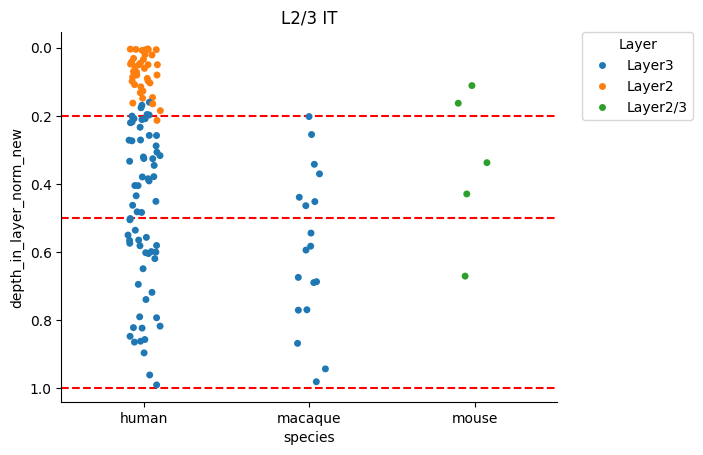

In [24]:
subclass = 'L2/3 IT'

#primate
this_human_data = human_data[human_data.subclass == subclass]
this_macaque_data = macaque_data[macaque_data.subclass == subclass]

this_human_data.specimen_id = this_human_data.specimen_id.astype(int)
this_macaque_data.specimen_id = this_macaque_data.specimen_id.astype(int)

this_human_soma_depths = human_soma_depths.merge(this_human_data, how='inner', on='specimen_id')
this_macaque_soma_depths = macaque_soma_depths.merge(this_macaque_data, how='inner', on='specimen_id')

this_human_soma_depths = this_human_soma_depths[this_human_soma_depths.layer_new == 'Layer2/3'] 
this_macaque_soma_depths = this_macaque_soma_depths[this_macaque_soma_depths.layer_new == 'Layer2/3']

this_human_soma_depths['species'] = 'human'
this_macaque_soma_depths['species'] = 'macaque'

#mouse 
mouse_l23 = mouse_data[mouse_data[subclass_col] == 'L2/3 IT'][['specimen_id', 'species', 'subclass', 'cluster', 'soma_aligned_dist_from_pia']].sort_values(by='soma_aligned_dist_from_pia')

m_layers, m_labels, m_colors = load_layer_template('mouse')

wm = m_layers['wm']
layer_top = m_layers['2/3'] 
layer_bottom = m_layers['4'] 

mouse_l23 = mouse_l23[(mouse_l23.soma_aligned_dist_from_pia > layer_top)  & (mouse_l23.soma_aligned_dist_from_pia < layer_bottom)]

if depth_type == 'pia':
    depth_column = 'depth_from_pia_norm'
    mouse_l23[depth_column] = mouse_l23.soma_aligned_dist_from_pia / wm
else:
    depth_column = 'depth_in_layer_norm_new'
    mouse_l23[depth_column] = (mouse_l23.soma_aligned_dist_from_pia - layer_top) / (layer_bottom - layer_top)

mouse_l23['layer'] = 'Layer2/3'
mouse_l23['layer_new'] = 'Layer2/3'

#merge species normed depth in layer
soma_depth_data = pd.concat([this_human_soma_depths, this_macaque_soma_depths, mouse_l23])

fig, ax = plt.subplots()
sns.stripplot(soma_depth_data, x='species', y=depth_column, hue='layer')

if depth_type == 'pia':
    #thresholds for defining superficial and deep from depth_from_pia_norm 
    lower_thresh = 0.15
    middle_thresh = 0.25
    upper_thresh = 0.45
else:
    #thresholds for defining superficial and deep from depth_in_layer_norm 
    lower_thresh = 0.2
    middle_thresh = 0.5
    upper_thresh = 1

plt.axhline(lower_thresh, linestyle='--', c='r')
plt.axhline(middle_thresh, linestyle='--', c='r')
plt.axhline(upper_thresh, linestyle='--', c='r')
plt.title(subclass)
ax.invert_yaxis()
sns.despine()

# Move legend outside
ax.legend(
    title='Layer',
    bbox_to_anchor=(1.05, 1),
    loc='upper left',
    borderaxespad=0.
)


# Save to PDF
pdf_path = os.path.join(OUT_DIR, f"l23_superficial_deep_soma_depths_{depth_type}.pdf")
plt.savefig(pdf_path, format='pdf', bbox_inches='tight')
plt.show()
plt.close()


In [25]:
# #Temp save for Brian
# mouse_l23.to_csv(os.path.join(output_dir, 'mouse_depth_from_pia_norm.csv'), index=False)
# this_macaque_soma_depths.to_csv(os.path.join(output_dir, 'macaque_depth_from_pia_norm.csv'), index=False)


In [26]:
# define the group based on thresholds    
def categorize_depth_2(val):
    if val < middle_thresh:
        return 'superficial'
    else:
        return 'deep'


#remove 'L2' (because macaque doesn't have any) 
soma_depth_data = soma_depth_data[soma_depth_data.layer != 'Layer2']

#remove cells below lower thresh and above upper thresh 
soma_depth_data = soma_depth_data[soma_depth_data[depth_column] > lower_thresh]
soma_depth_data = soma_depth_data[soma_depth_data[depth_column] < upper_thresh]

#create deep and superficial groups
soma_depth_data['depth_group_two'] = soma_depth_data[depth_column].apply(categorize_depth_2)



2026-09-23 21:33:03,511 fontTools.subset INFO     maxp pruned
2026-09-23 21:33:03,522 fontTools.subset INFO     cmap pruned
2026-09-23 21:33:03,523 fontTools.subset INFO     kern dropped
2026-09-23 21:33:03,523 fontTools.subset INFO     post pruned
2026-09-23 21:33:03,524 fontTools.subset INFO     FFTM dropped
2026-09-23 21:33:03,526 fontTools.subset INFO     GPOS pruned
2026-09-23 21:33:03,530 fontTools.subset INFO     GSUB pruned
2026-09-23 21:33:03,538 fontTools.subset INFO     glyf pruned
2026-09-23 21:33:03,539 fontTools.subset INFO     Added gid0 to subset
2026-09-23 21:33:03,540 fontTools.subset INFO     Added first four glyphs to subset
2026-09-23 21:33:03,541 fontTools.subset INFO     Closing glyph list over 'MATH': 39 glyphs before
2026-09-23 21:33:03,541 fontTools.subset INFO     Glyph names: ['.notdef', '.null', 'I', 'L', 'T', 'a', 'c', 'd', 'e', 'eight', 'f', 'five', 'four', 'h', 'i', 'l', 'm', 'n', 'nine', 'nonmarkingreturn', 'o', 'one', 'p', 'period', 'q', 'r', 's', 'sev

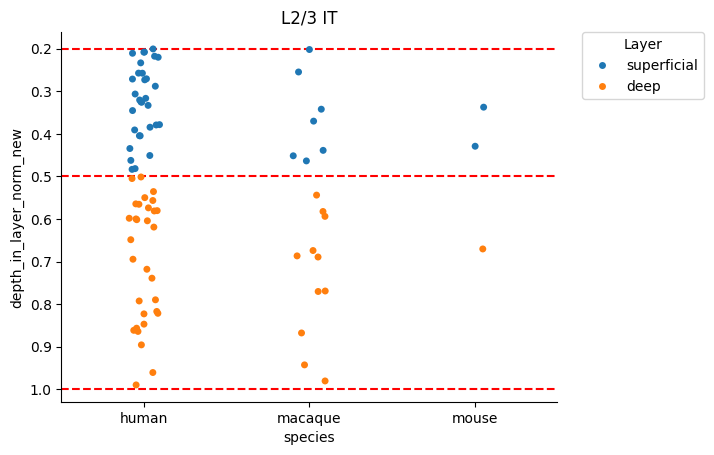

In [27]:

fig, ax = plt.subplots()
sns.stripplot(soma_depth_data, x='species', y=depth_column, hue='depth_group_two')
plt.axhline(lower_thresh, linestyle='--', c='r')
plt.axhline(middle_thresh, linestyle='--', c='r')
plt.axhline(upper_thresh, linestyle='--', c='r')
plt.title(subclass)
ax.invert_yaxis()
sns.despine()

# Move legend outside
ax.legend(
    title='Layer',
    bbox_to_anchor=(1.05, 1),
    loc='upper left',
    borderaxespad=0.
)

# Save to PDF
pdf_path = os.path.join(OUT_DIR, f"l23_superficial_deep_soma_depths_{depth_type}_filtered.pdf")
plt.savefig(pdf_path, format='pdf', bbox_inches='tight')
plt.show()
plt.close()

In [28]:
# count number of cells per species per group
group_counts = soma_depth_data.groupby(['species', 'depth_group_two']).size().unstack(fill_value=0)
print(group_counts)

depth_group_two  deep  superficial
species                           
human              31           31
macaque            11            7
mouse               1            2


In [29]:
soma_depth_data[['specimen_id', 'species', depth_column, 'depth_group_two']]

,specimen_id,species,depth_in_layer_norm_new,depth_group_two
0,737134157,human,0.325230,superficial
1,588157408,human,0.580446,deep
2,774620186,human,0.404754,superficial
3,737133884,human,0.345425,superficial
4,774420848,human,0.598338,deep
...,...,...,...,...
16,1161553245,macaque,0.342210,superficial
17,1217796585,macaque,0.942628,deep
23,1474090647,mouse,0.337460,superficial
22,1474084154,mouse,0.429203,superficial


In [30]:
#save species data for plotting
soma_depth_data[['specimen_id', 'species', depth_column,  'depth_group_two']].to_csv(os.path.join(OUT_DIR, f'l23_comparison_{depth_type}.csv'), index=False)


## L5 IT and L5 ET Depth by Species

2026-09-23 21:28:50,780 fontTools.subset INFO     maxp pruned
2026-09-23 21:28:50,790 fontTools.subset INFO     cmap pruned
2026-09-23 21:28:50,791 fontTools.subset INFO     kern dropped
2026-09-23 21:28:50,792 fontTools.subset INFO     post pruned
2026-09-23 21:28:50,792 fontTools.subset INFO     FFTM dropped
2026-09-23 21:28:50,795 fontTools.subset INFO     GPOS pruned
2026-09-23 21:28:50,799 fontTools.subset INFO     GSUB pruned
2026-09-23 21:28:50,807 fontTools.subset INFO     glyf pruned
2026-09-23 21:28:50,808 fontTools.subset INFO     Added gid0 to subset
2026-09-23 21:28:50,809 fontTools.subset INFO     Added first four glyphs to subset
2026-09-23 21:28:50,809 fontTools.subset INFO     Closing glyph list over 'MATH': 38 glyphs before
2026-09-23 21:28:50,810 fontTools.subset INFO     Glyph names: ['.notdef', '.null', 'D', 'I', 'L', 'S', 'T', 'a', 'b', 'c', 'd', 'e', 'eight', 'five', 'four', 'h', 'hyphen', 'i', 'l', 'm', 'n', 'nonmarkingreturn', 'o', 'one', 'p', 'period', 'q', 'r

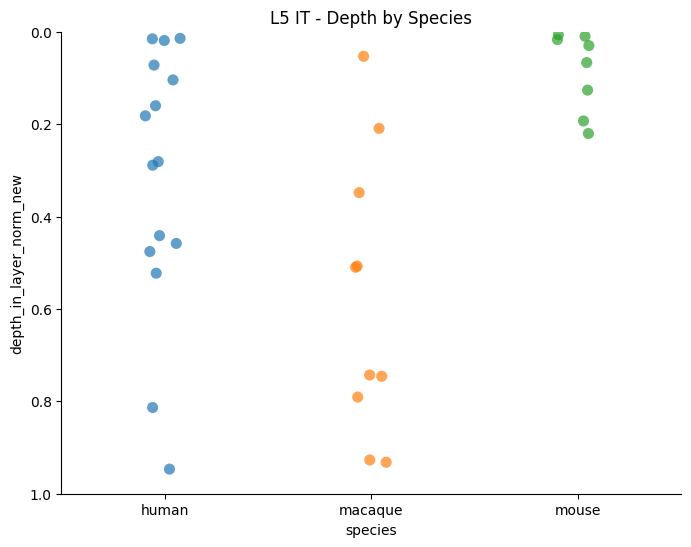

L5 IT cell counts per species:
human      15
macaque    10
mouse       8
Name: species, dtype: int64


In [16]:
# L5 IT Depth x Species
subclass = 'L5 IT'

# Primate data
this_human_data = human_data[human_data.subclass == subclass].copy()
this_macaque_data = macaque_data[macaque_data.subclass == subclass].copy()

this_human_data.specimen_id = this_human_data.specimen_id.astype(int)
this_macaque_data.specimen_id = this_macaque_data.specimen_id.astype(int)

this_human_soma_depths = human_soma_depths.merge(this_human_data, how='inner', on='specimen_id')
this_macaque_soma_depths = macaque_soma_depths.merge(this_macaque_data, how='inner', on='specimen_id')

this_human_soma_depths = this_human_soma_depths[this_human_soma_depths.layer_new == 'Layer5']
this_macaque_soma_depths = this_macaque_soma_depths[this_macaque_soma_depths.layer_new == 'Layer5']

this_human_soma_depths['species'] = 'human'
this_macaque_soma_depths['species'] = 'macaque'

# Mouse data
mouse_l5 = mouse_data[mouse_data[subclass_col] == 'L5 IT'][['specimen_id', 'species', 'subclass', 'cluster', 'soma_aligned_dist_from_pia']].sort_values(by='soma_aligned_dist_from_pia')

m_layers, m_labels, m_colors = load_layer_template('mouse')

wm = m_layers['wm']
layer_top = m_layers['5']
layer_bottom = wm  # Use white matter as bottom boundary

mouse_l5 = mouse_l5[(mouse_l5.soma_aligned_dist_from_pia > layer_top) & (mouse_l5.soma_aligned_dist_from_pia < layer_bottom)]

if depth_type == 'pia':
    depth_column = 'depth_from_pia_norm'
    mouse_l5[depth_column] = mouse_l5.soma_aligned_dist_from_pia / wm
else:
    depth_column = 'depth_in_layer_norm_new'
    mouse_l5[depth_column] = (mouse_l5.soma_aligned_dist_from_pia - layer_top) / (layer_bottom - layer_top)

mouse_l5['layer'] = 'Layer5'
mouse_l5['layer_new'] = 'Layer5'

# Merge species normed depth in layer
soma_depth_data_l5it = pd.concat([this_human_soma_depths, this_macaque_soma_depths, mouse_l5])

fig, ax = plt.subplots(figsize=(8, 6))
sns.stripplot(soma_depth_data_l5it, x='species', y=depth_column, hue='species', s=8, alpha=0.7)
plt.title(f'{subclass} - Depth by Species')
plt.ylabel(depth_column)
plt.ylim(0, 1)
ax.invert_yaxis()
sns.despine()

# Remove legend since species is on x-axis
if ax.legend_:
    ax.legend_.remove()

# Save to PDF
pdf_path = os.path.join(OUT_DIR, f"l5_it_depth_by_species_{depth_type}.pdf")
plt.savefig(pdf_path, format='pdf', bbox_inches='tight')
plt.show()
plt.close()

print(f"L5 IT cell counts per species:")
print(soma_depth_data_l5it.species.value_counts())

2026-09-23 21:28:51,401 fontTools.subset INFO     maxp pruned
2026-09-23 21:28:51,412 fontTools.subset INFO     cmap pruned
2026-09-23 21:28:51,412 fontTools.subset INFO     kern dropped
2026-09-23 21:28:51,413 fontTools.subset INFO     post pruned
2026-09-23 21:28:51,413 fontTools.subset INFO     FFTM dropped
2026-09-23 21:28:51,415 fontTools.subset INFO     GPOS pruned
2026-09-23 21:28:51,419 fontTools.subset INFO     GSUB pruned
2026-09-23 21:28:51,426 fontTools.subset INFO     glyf pruned
2026-09-23 21:28:51,427 fontTools.subset INFO     Added gid0 to subset
2026-09-23 21:28:51,428 fontTools.subset INFO     Added first four glyphs to subset
2026-09-23 21:28:51,428 fontTools.subset INFO     Closing glyph list over 'MATH': 38 glyphs before
2026-09-23 21:28:51,428 fontTools.subset INFO     Glyph names: ['.notdef', '.null', 'D', 'E', 'L', 'S', 'T', 'a', 'b', 'c', 'd', 'e', 'eight', 'five', 'four', 'h', 'hyphen', 'i', 'l', 'm', 'n', 'nonmarkingreturn', 'o', 'one', 'p', 'period', 'q', 'r

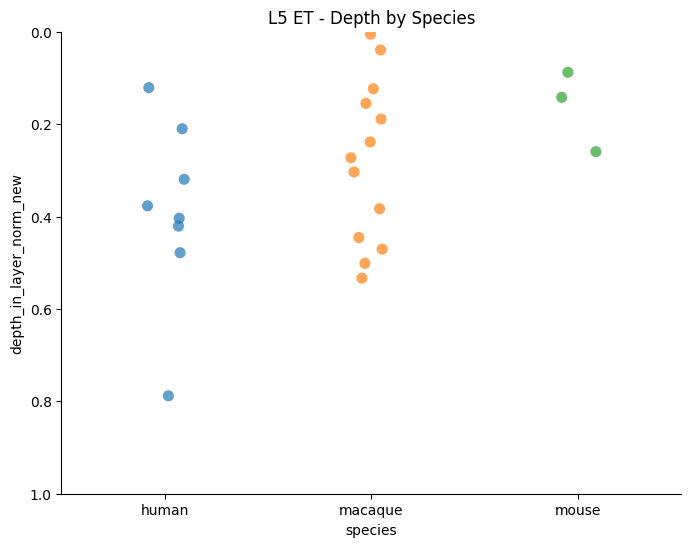

L5 ET cell counts per species:
macaque    13
human       8
mouse       3
Name: species, dtype: int64


In [17]:
# L5 ET Depth x Species
subclass = 'L5 ET'

# Primate data
this_human_data = human_data[human_data.subclass == subclass].copy()
this_macaque_data = macaque_data[macaque_data.subclass == subclass].copy()

this_human_data.specimen_id = this_human_data.specimen_id.astype(int)
this_macaque_data.specimen_id = this_macaque_data.specimen_id.astype(int)

this_human_soma_depths = human_soma_depths.merge(this_human_data, how='inner', on='specimen_id')
this_macaque_soma_depths = macaque_soma_depths.merge(this_macaque_data, how='inner', on='specimen_id')

this_human_soma_depths = this_human_soma_depths[this_human_soma_depths.layer_new == 'Layer5']
this_macaque_soma_depths = this_macaque_soma_depths[this_macaque_soma_depths.layer_new == 'Layer5']

this_human_soma_depths['species'] = 'human'
this_macaque_soma_depths['species'] = 'macaque'

# Mouse data
mouse_l5 = mouse_data[mouse_data[subclass_col] == 'L5 ET'][['specimen_id', 'species', 'subclass', 'cluster', 'soma_aligned_dist_from_pia']].sort_values(by='soma_aligned_dist_from_pia')

m_layers, m_labels, m_colors = load_layer_template('mouse')

wm = m_layers['wm']
layer_top = m_layers['5']
layer_bottom = wm  # Use white matter as bottom boundary

mouse_l5 = mouse_l5[(mouse_l5.soma_aligned_dist_from_pia > layer_top) & (mouse_l5.soma_aligned_dist_from_pia < layer_bottom)]

if depth_type == 'pia':
    depth_column = 'depth_from_pia_norm'
    mouse_l5[depth_column] = mouse_l5.soma_aligned_dist_from_pia / wm
else:
    depth_column = 'depth_in_layer_norm_new'
    mouse_l5[depth_column] = (mouse_l5.soma_aligned_dist_from_pia - layer_top) / (layer_bottom - layer_top)

mouse_l5['layer'] = 'Layer5'
mouse_l5['layer_new'] = 'Layer5'

# Merge species normed depth in layer
soma_depth_data_l5et = pd.concat([this_human_soma_depths, this_macaque_soma_depths, mouse_l5])

fig, ax = plt.subplots(figsize=(8, 6))
sns.stripplot(soma_depth_data_l5et, x='species', y=depth_column, hue='species', s=8, alpha=0.7)
plt.title(f'{subclass} - Depth by Species')
plt.ylabel(depth_column)
plt.ylim(0, 1)
ax.invert_yaxis()
sns.despine()

# Remove legend since species is on x-axis
if ax.legend_:
    ax.legend_.remove()

# Save to PDF
pdf_path = os.path.join(OUT_DIR, f"l5_et_depth_by_species_{depth_type}.pdf")
plt.savefig(pdf_path, format='pdf', bbox_inches='tight')
plt.show()
plt.close()

print(f"L5 ET cell counts per species:")
print(soma_depth_data_l5et.species.value_counts())